<a href="https://colab.research.google.com/github/jeisteve999/African-Public-Contracts-Red-Flags-and-Outlier-Analysis/blob/main/African_Public_Contracts_Red_Flags_and_Outlier_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import sqlite3

In [4]:
df = pd.read_csv('/content/contratos_africanos_redflags (1).csv')

def clean_data(dirty_data):
    text = str(dirty_data)
    text = text.replace("KES", "").replace("UGX", "").replace("reales", "").replace(",", "").strip()
    return float(text)

df["clean_data"] = df["tender_value"].apply(clean_data)


In [6]:
#  creating a temporary SQL database directly in Python's memory.

conexion_sql = sqlite3.connect(":memory:")

# Saving our clean DataFrame as an SQL table called 'contracts'

df.to_sql("Contracts", conexion_sql, index=False, if_exists = "replace")

# writting our query in SQL language

query_sql = """
SELECT
      buyer_name AS ministery,
      COUNT(tender_id) AS total_contracts,
      SUM(clean_data) AS total_budget,
      SUM(single_bidding) AS alerts_unique_bidders
from contracts
GROUP BY buyer_name
ORDER BY total_budget DESC
LIMIT 5

"""

sql_result = pd.read_sql_query(query_sql, conexion_sql)

print(sql_result)



                          ministery  total_contracts  total_budget  \
0             Ministry of Education               12     4418545.0   
1         Ministry of Health Uganda                8     3662578.0   
2           National Road Authority                5     3333307.0   
3   Ministry of Works and Transport                6     3076267.0   
4  Ministry of Education and Sports                9     2832310.0   

   alerts_unique_bidders  
0                      6  
1                      3  
2                      1  
3                      1  
4                      1  


In [10]:
# Descriptive statistics
# Central tendency and dispersion measures

mean_amount = df["clean_data"].mean()
median_amount = df["clean_data"].median()
std_dev = df["clean_data"].std()

print(f" Average contract value: ${mean_amount:.2f}")
print(f" Median contract value: ${median_amount:.2f}")
print(f" Standard deviation: ${std_dev:,.2f}")

# Quartile analysis and outlier detection (IQR Method)

q1= df["clean_data"].quantile(0.25)
q3 = df["clean_data"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + (1.5 * iqr)

print(f"\n-- Distribution Analysis (Quartiles)---")
print(f" Q1 (25th Percentile): ${q1:,.2f}")
print(f" Q3 (75th Percentile): ${q3:,.2f}")
print(f" Upper Outlier Threshold: ${upper_bound:,.2f}")

# Filter contracts exceeding the upper threshold

outliers = df[df["clean_data"]> upper_bound]
print(f"Total Outlier Contracts Detected:{len(outliers)}")

 Average contract value: $387324.18
 Median contract value: $335309.50
 Standard deviation: $250,586.27

-- Distribution Analysis (Quartiles)---
 Q1 (25th Percentile): $182,562.75
 Q3 (75th Percentile): $591,724.50
 Upper Outlier Threshold: $1,205,467.12
Total Outlier Contracts Detected:0


# The average contract value is 387,324 USD, with a median of 335,310 USD, indicating a slight right skew. The standard deviation of 250,586 USD shows considerable variability. The middle 50% of contracts range from 182,563 USD to 591,725 USD. Using the IQR method, the upper outlier threshold is 1,205,467 USD, and no contracts exceed it, so no outliers were detected.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<>:30: SyntaxWarning: invalid escape sequence '\$'
<>:30: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_630/224725648.py:30: SyntaxWarning: invalid escape sequence '\$'
  label = f"Outlier Threshold (\${upper_bound:,.0f})"


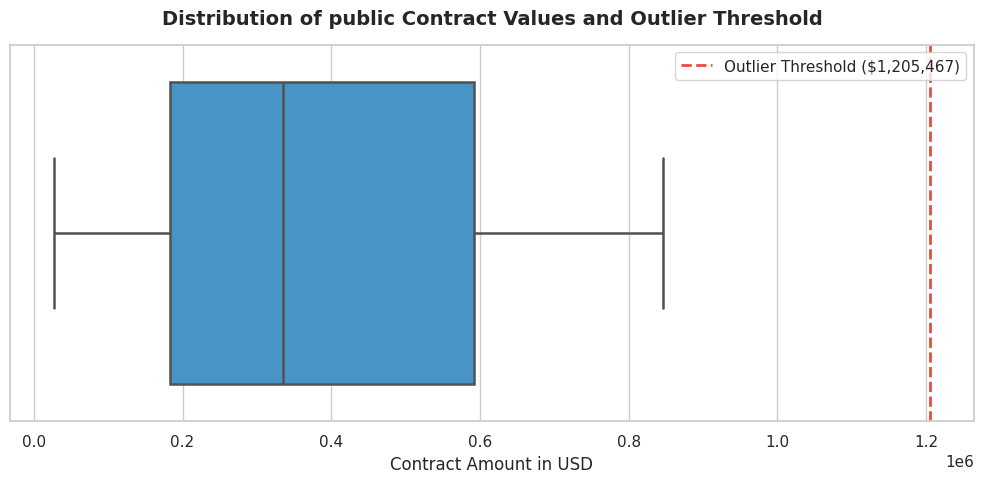

In [27]:
# set visual style

sns.set_theme(style = "whitegrid")
plt.figure(figsize=(10,5))

# Create horizontal boxplot

ax = sns.boxplot(
    x=df["clean_data"],
    color="#3498db",
    fliersize=6,
    linewidth=1.8
)


# Calculate threshold for the visual reference line

q1= df["clean_data"].quantile(0.25)
q3= df["clean_data"].quantile(0.75)
iqr = q3-q1
upper_bound= q3 + 1.5 * iqr

# Add red dashed line for the oulier threshold

plt.axvline(
    upper_bound,
    color = "#e74c3c",
    linestyle = "--",
    linewidth = 2,
    label = f"Outlier Threshold (\${upper_bound:,.0f})"
)

# Formatting labels and title
plt.title("Distribution of public Contract Values and Outlier Threshold", fontsize = 14, fontweight= "bold", pad=15)
plt.xlabel("Contract Amount in USD", fontsize= 12)
plt.legend(loc = "upper right")
label = f"Outlier Threshold (${upper_bound:,.0f})"
plt.tight_layout()
plt.show()

# The boxplot shows that the middle 50% of contracts range from 182,563 USD to 591,725 USD, with a median of 335,310 USD. The longer right whisker suggests a slight right skew. The red dashed line marks the outlier threshold at 1,205,467 USD, and no contracts exceed it, so no outliers were detected.